In [2]:
import joblib
import pandas as pd

In [3]:
df=pd.read_csv('/content/master_analytical_matrix_cpcb_2025.csv')

In [4]:
df.head()

,timestamp,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,wind_gusts_10m,precipitation,cloud_cover,...,wind_alignment_chandrapur_midc,downwind_dispersion_chandrapur_midc,dist_to_amravati_central_km,idw_weight_amravati_central,wind_alignment_amravati_central,downwind_dispersion_amravati_central,dist_to_akola_west_km,idw_weight_akola_west,wind_alignment_akola_west,downwind_dispersion_akola_west
0,2025-02-19 01:00:00,23.2,47,11.3,977.9,8.2,256,14.4,0.0,0,...,0.835,6.847,84.402,0.000137,0.997,8.179,0.000,1.000000,-0.242,-1.984
1,2025-02-19 01:00:00,23.5,45,10.9,970.1,2.1,52,13.0,0.0,0,...,-0.297,-0.623,0.000,1.000000,0.616,1.293,84.402,0.000137,0.942,1.978
2,2025-02-19 01:00:00,23.6,43,10.3,987.9,6.6,169,11.9,0.0,0,...,-0.982,-6.479,191.673,0.000027,0.710,4.684,252.295,0.000016,0.494,3.260
3,2025-02-19 01:00:00,24.8,40,10.3,976.2,8.1,1,19.1,0.0,0,...,0.984,7.969,137.769,0.000052,0.189,1.534,221.642,0.000020,0.247,1.999
4,2025-02-19 02:00:00,22.7,49,11.5,977.2,9.0,276,15.8,0.0,0,...,0.973,8.755,84.402,0.000137,0.913,8.217,0.000,1.000000,0.105,0.941


## Phase 1


###Step 1: Ingestion & Structure.

Quick Summary of Your Data:
- Total Size: 28,070 rows and 53 columns.
- Types of Columns: 51 Numerical Columns and 2 Categorical Columns (timestamp, station_id).
- Missing Values: Interestingly, your initial info() call shows 28070 non-null across the visible columns, meaning the dataset is already extremely complete or pre-aligned.

In [5]:
import pandas as pd
import numpy as np

# Step 1: Ingestion & Structure
# The dataset is located at '/content/master_analytical_matrix_cpcb_2025.csv'
file_path = '/content/master_analytical_matrix_cpcb_2025.csv'
df = pd.read_csv(file_path)

# 1. Shape of the dataset
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

# 2. General Information
print("--- Dataset Info ---")
df.info()

# 3. Separate Features into Numerical and Categorical
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("\n--- Feature Classification ---")
print(f"Numerical Columns ({len(numerical_cols)}): {numerical_cols[:10]}... (showing first 10)")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

# 4. Display the first 5 rows
print("\n--- First 5 Rows ---")
display(df.head())

Dataset Shape: 28070 rows, 53 columns

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28070 entries, 0 to 28069
Data columns (total 53 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   timestamp                             28070 non-null  object 
 1   temperature_2m                        28070 non-null  float64
 2   relative_humidity_2m                  28070 non-null  int64  
 3   dew_point_2m                          28070 non-null  float64
 4   surface_pressure                      28070 non-null  float64
 5   wind_speed_10m                        28070 non-null  float64
 6   wind_direction_10m                    28070 non-null  int64  
 7   wind_gusts_10m                        28070 non-null  float64
 8   precipitation                         28070 non-null  float64
 9   cloud_cover                           28070 non-null  int64  
 10  direct_radiation      

,timestamp,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,wind_gusts_10m,precipitation,cloud_cover,...,wind_alignment_chandrapur_midc,downwind_dispersion_chandrapur_midc,dist_to_amravati_central_km,idw_weight_amravati_central,wind_alignment_amravati_central,downwind_dispersion_amravati_central,dist_to_akola_west_km,idw_weight_akola_west,wind_alignment_akola_west,downwind_dispersion_akola_west
0,2025-02-19 01:00:00,23.2,47,11.3,977.9,8.2,256,14.4,0.0,0,...,0.835,6.847,84.402,0.000137,0.997,8.179,0.000,1.000000,-0.242,-1.984
1,2025-02-19 01:00:00,23.5,45,10.9,970.1,2.1,52,13.0,0.0,0,...,-0.297,-0.623,0.000,1.000000,0.616,1.293,84.402,0.000137,0.942,1.978
2,2025-02-19 01:00:00,23.6,43,10.3,987.9,6.6,169,11.9,0.0,0,...,-0.982,-6.479,191.673,0.000027,0.710,4.684,252.295,0.000016,0.494,3.260
3,2025-02-19 01:00:00,24.8,40,10.3,976.2,8.1,1,19.1,0.0,0,...,0.984,7.969,137.769,0.000052,0.189,1.534,221.642,0.000020,0.247,1.999
4,2025-02-19 02:00:00,22.7,49,11.5,977.2,9.0,276,15.8,0.0,0,...,0.973,8.755,84.402,0.000137,0.913,8.217,0.000,1.000000,0.105,0.941


### Step 2: Descriptive Statistics

- Data Completeness: All 53 columns show exactly 28070 non-null records. This suggests that the numerical columns are fully populated or have been pre-cleaned/imputed in an earlier version of the pipeline.
- Target Candidates & Ranges:
 - - pm2_5: ranges from 2.0 to 154.6 µg/m³ (Mean: 30.1).
  - - pm10: ranges from 2.1 to 238.4 µg/m³ (Mean: 38.9).
- - carbon_monoxide: ranges from 113.0 to 1351.0 (Mean: 299.4).
- - All environmental pollutants have positive minimum values (no negative values found, which is a great sign since negative pollutant concentrations would be anomalous).
- Categorical Features:
station_id has 4 unique monitoring stations, with NAGPUR_CENTRAL being the most frequent (7,174 times).
timestamp has 7,338 unique intervals.

In [6]:
# Step 2: Descriptive Statistics

# 1. Summary statistics for key numerical columns
print("--- Numerical Features Descriptive Statistics ---")
# Since there are 51 columns, we will describe a few representative weather and pollution metrics to keep it readable, as well as the whole dataset summarized.
print(df[numerical_cols].describe().transpose())

# 2. Summary statistics for categorical columns
print("\n--- Categorical Features Descriptive Statistics ---")
print(df[categorical_cols].describe())

# 3. Quick anomaly check (e.g., min value check for concentrations)
pollution_cols = [col for col in ['pm2_5', 'pm10', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'carbon_monoxide'] if col in df.columns]
if pollution_cols:
    print("\n--- Minimum and Maximum Values for Key Pollutants ---")
    for col in pollution_cols:
        print(f"{col} -> Min: {df[col].min()}, Max: {df[col].max()}")

--- Numerical Features Descriptive Statistics ---
                                        count        mean         std  \
temperature_2m                        28070.0   27.533060    5.520654   
relative_humidity_2m                  28070.0   59.341005   26.141635   
dew_point_2m                          28070.0   16.837463    7.162595   
surface_pressure                      28070.0  974.664100    8.243718   
wind_speed_10m                        28070.0    8.730581    4.634572   
wind_direction_10m                    28070.0  209.132918  102.589804   
wind_gusts_10m                        28070.0   21.270403    9.918160   
precipitation                         28070.0    0.171076    0.769569   
cloud_cover                           28070.0   50.505308   44.901726   
direct_radiation                      28070.0  144.377271  222.306024   
latitude                              28070.0   20.696625    0.442693   
longitude                             28070.0   78.283996    0.940889   
d

## Phase 2: Data Quality Issues & Cleaning

#### Step 3 (Missing Values & Duplicates) are complete:

- Missing values: 0% missing across all columns.
- Duplicates: Exactly 0 duplicate rows found. This means our dataset remains at a clean 28,070 rows.

In [7]:
# Step 3: Missing Values & Duplicates

# 1. Check for missing values (absolute sum and percentage)
missing_counts = df.isnull().sum()
missing_percentages = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percentages
}).sort_values(by='Missing Count', ascending=False)

print("--- Missing Values Check (Top 10 columns with missing values) ---")
print(missing_df.head(10))

# 2. Check for duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\n--- Duplicates Check ---\nTotal duplicate rows found: {duplicate_count}")

# 3. Strategy/Handling
if duplicate_count > 0:
    print("\nAction: Removing duplicate rows...")
    df = df.drop_duplicates()
    print(f"New dataset shape after removing duplicates: {df.shape}")
else:
    print("\nAction: No duplicates to remove.")

--- Missing Values Check (Top 10 columns with missing values) ---
                      Missing Count  Percentage (%)
timestamp                         0             0.0
temperature_2m                    0             0.0
relative_humidity_2m              0             0.0
dew_point_2m                      0             0.0
surface_pressure                  0             0.0
wind_speed_10m                    0             0.0
wind_direction_10m                0             0.0
wind_gusts_10m                    0             0.0
precipitation                     0             0.0
cloud_cover                       0             0.0

--- Duplicates Check ---
Total duplicate rows found: 0

Action: No duplicates to remove.


In [8]:
# Step 4: Outlier Detection using IQR

# We will focus on key pollutant variables
target_pollutants = ['pm2_5', 'pm10', 'carbon_monoxide']

print("--- Outlier Detection Analysis (IQR Method) ---")
for col in target_pollutants:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Identify outliers
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_percentage = (len(outliers) / len(df)) * 100

        print(f"{col.upper()}:")
        print(f"  IQR: {IQR:.2f} (Q1: {Q1:.2f}, Q3: {Q3:.2f})")
        print(f"  Outlier Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
        print(f"  Number of Outliers: {len(outliers)} ({outlier_percentage:.2f}% of total data)")
        print(f"  Min Outlier Value: {outliers[col].min() if len(outliers) > 0 else 'N/A'}")
        print(f"  Max Outlier Value: {outliers[col].max() if len(outliers) > 0 else 'N/A'}\n")

--- Outlier Detection Analysis (IQR Method) ---
PM2_5:
  IQR: 22.10 (Q1: 16.50, Q3: 38.60)
  Outlier Bounds: [-16.65, 71.75]
  Number of Outliers: 1142 (4.07% of total data)
  Min Outlier Value: 71.9
  Max Outlier Value: 154.6

PM10:
  IQR: 31.10 (Q1: 21.20, Q3: 52.30)
  Outlier Bounds: [-25.45, 98.95]
  Number of Outliers: 547 (1.95% of total data)
  Min Outlier Value: 99.0
  Max Outlier Value: 238.4

CARBON_MONOXIDE:
  IQR: 164.00 (Q1: 202.00, Q3: 366.00)
  Outlier Bounds: [-44.00, 612.00]
  Number of Outliers: 791 (2.82% of total data)
  Min Outlier Value: 613.0
  Max Outlier Value: 1351.0



Step 4 has completed with the following insights:

- PM2.5: 4.07% of the dataset consists of values above the IQR statistical upper bound (values above 71.75 µg/m³ up to 154.6 µg/m³).
- PM10: 1.95% of the dataset contains outliers (values above 98.95 µg/m³ up to 238.4 µg/m³).
- Carbon Monoxide (CO): 2.82% of the dataset consists of outliers (values above 612.0 up to 1351.0).
- Since this is air quality data, these higher levels represent real, highly critical peak pollution events rather than sensory errors. Thus, we should preserve them for our regression training to ensure our models can accurately predict extreme events.

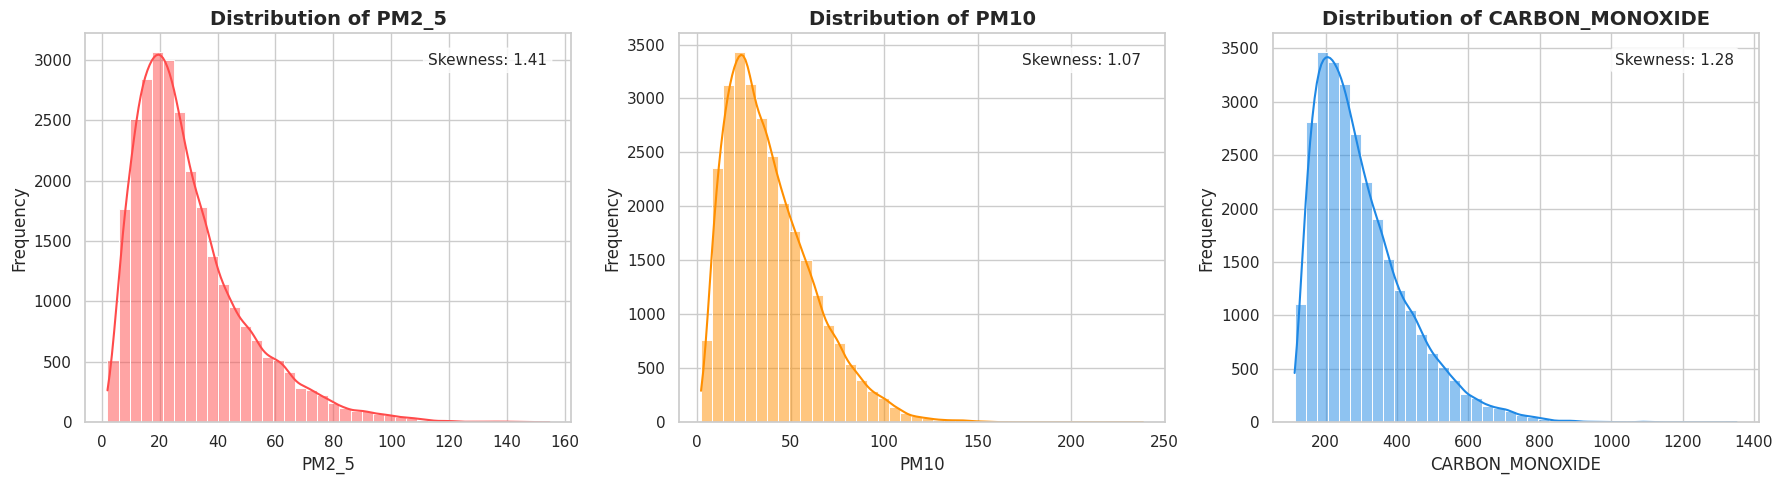

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 5: Statistical Graphs (Distribution Plots)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# List of key targets to plot
targets = ['pm2_5', 'pm10', 'carbon_monoxide']
colors = ['#FF4B4B', '#FF8F00', '#1E88E5']

for idx, (col, color) in enumerate(zip(targets, colors)):
    sns.histplot(df[col], kde=True, color=color, ax=axes[idx], bins=40)
    axes[idx].set_title(f'Distribution of {col.upper()}', fontsize=14, fontweight='bold')
    axes[idx].set_xlabel(col.upper(), fontsize=12)
    axes[idx].set_ylabel('Frequency', fontsize=12)

    # Display skewness
    skewness = df[col].skew()
    axes[idx].text(0.95, 0.95, f'Skewness: {skewness:.2f}',
                  transform=axes[idx].transAxes,
                  verticalalignment='top',
                  horizontalalignment='right',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=11)

plt.tight_layout()
plt.show()

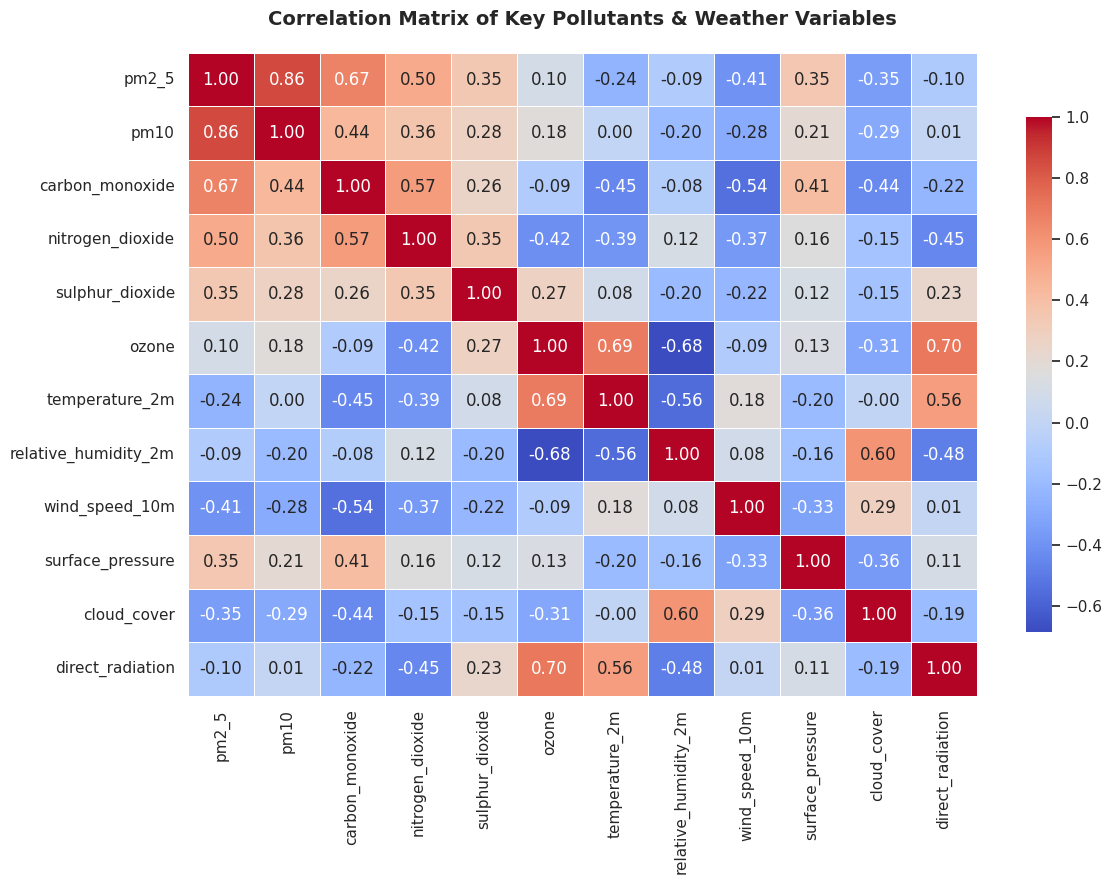

In [10]:
# Step 6: Correlation Analysis
import matplotlib.pyplot as plt
import seaborn as sns

# Select a representative subset of columns to avoid a cluttered heatmap
core_cols = [
    'pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone',
    'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'surface_pressure',
    'cloud_cover', 'direct_radiation','india_naqi'
]

# Filter columns that actually exist in the dataframe
selected_cols = [col for col in core_cols if col in df.columns]

# Compute correlation matrix
corr_matrix = df[selected_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix of Key Pollutants & Weather Variables', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [11]:
# Step 7: Data Transformation
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Define target column
target_col = 'india_naqi'

# Define feature columns: drop target, timestamp, and potentially the target duplicate cams_satellite_naqi to prevent data leakage
ignore_cols = ['timestamp', 'cams_satellite_naqi', target_col]
feature_cols = [col for col in df.columns if col not in ignore_cols]

X = df[feature_cols].copy()
y = df[target_col].copy()

# Identify categorical columns to encode (e.g., station_id)
cat_features = X.select_dtypes(include=['object']).columns.tolist()
num_features = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Target variable: {target_col}")
print(f"Categorical features to encode: {cat_features}")
print(f"Numerical features to scale: {len(num_features)} columns\n")

# One-Hot Encode categorical features
X_encoded = pd.get_dummies(X, columns=cat_features, drop_first=True)

# Scale numerical features
scaler = StandardScaler()
X_scaled_num = scaler.fit_transform(X_encoded[num_features])

# Reconstruct scaled DataFrame with encoded categorical features
X_final = X_encoded.copy()
X_final[num_features] = X_scaled_num

print(f"Final transformed feature matrix shape: {X_final.shape}")
display(X_final.head())

Target variable: india_naqi
Categorical features to encode: ['station_id']
Numerical features to scale: 49 columns

Final transformed feature matrix shape: (28070, 52)


,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,wind_gusts_10m,precipitation,cloud_cover,direct_radiation,...,idw_weight_amravati_central,wind_alignment_amravati_central,downwind_dispersion_amravati_central,dist_to_akola_west_km,idw_weight_akola_west,wind_alignment_akola_west,downwind_dispersion_akola_west,station_id_AMRAVATI_CENTRAL,station_id_CHANDRAPUR_MIDC,station_id_NAGPUR_CENTRAL
0,-0.784896,-0.472091,-0.773122,0.392536,-0.114485,0.456848,-0.692722,-0.222305,-1.124817,-0.649464,...,-0.581179,1.382756,1.124788,-1.355680,1.724107,-0.134762,-0.027539,False,False,False
1,-0.730553,-0.548598,-0.828969,-0.553656,-1.430703,-1.531689,-0.833879,-0.222305,-1.124817,-0.649464,...,1.720203,0.851557,0.153998,-0.529792,-0.579829,1.552902,0.538123,True,False,False
2,-0.712439,-0.625106,-0.912739,1.605603,-0.459723,-0.391205,-0.944789,-0.222305,-1.124817,-0.649464,...,-0.581432,0.982614,0.632062,1.113070,-0.580108,0.914326,0.721156,False,True,False
3,-0.495070,-0.739868,-0.912739,0.186315,-0.136063,-2.028824,-0.218835,-0.222305,-1.124817,-0.649464,...,-0.581374,0.256224,0.187974,0.813125,-0.580098,0.562254,0.541121,False,False,True
4,-0.875466,-0.395583,-0.745199,0.307621,0.058134,0.651802,-0.551564,-0.222305,-1.124817,-0.649464,...,-0.581179,1.265641,1.130145,-1.355680,1.724107,0.359849,0.390069,False,False,False


In [12]:
# Step 8: Train-Test Split
from sklearn.model_selection import train_test_split

# Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.2,
    random_state=42
)

print("--- Train-Test Split Completed ---")
print(f"Training Feature Set Shape (X_train): {X_train.shape}")
print(f"Testing Feature Set Shape (X_test):   {X_test.shape}")
print(f"Training Target Set Shape (y_train):  {y_train.shape}")
print(f"Testing Target Set Shape (y_test):    {y_test.shape}")

--- Train-Test Split Completed ---
Training Feature Set Shape (X_train): (22456, 52)
Testing Feature Set Shape (X_test):   (5614, 52)
Training Target Set Shape (y_train):  (22456,)
Testing Target Set Shape (y_test):    (5614,)


In [15]:
# Phase 5: Model Training & Comparison
# Step 9: Multi-Model Training & Step 10: Evaluation

import time
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Support Vector Regressor': SVR(kernel='rbf', C=10.0, epsilon=0.1, max_iter=5000),  # Limit max_iter for fast training
    'Decision Tree': DecisionTreeRegressor(random_state=42, max_depth=12),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100, max_depth=12, n_jobs=-1),
    'HistGradient Boosting': HistGradientBoostingRegressor(random_state=42)
}

results = []

print("--- Starting Model Training & Evaluation ---\n")

for name, model in models.items():
    t0 = time.time()

    # Train the model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    elapsed_time = time.time() - t0

    # Metrics calculation
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'R2 Score': round(r2, 4),
        'Training Time (s)': round(elapsed_time, 2)
    })
    print(f"Completed: {name} in {elapsed_time:.2f}s")

# Convert results to a DataFrame and sort by R2 Score descending
comparison_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("\n--- Final Model Comparison Table ---")
display(comparison_df)

--- Starting Model Training & Evaluation ---

Completed: Linear Regression in 0.08s
Completed: Ridge Regression in 0.04s


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Completed: Support Vector Regressor in 23.25s
Completed: Decision Tree in 0.86s
Completed: Random Forest in 47.91s
Completed: HistGradient Boosting in 1.85s

--- Final Model Comparison Table ---


,Model,MAE,MSE,RMSE,R2 Score,Training Time (s)
0,Random Forest,18.6154,1073.8613,32.7698,0.6718,47.91
1,HistGradient Boosting,19.0693,1084.3312,32.9292,0.6686,1.85
2,Support Vector Regressor,21.3867,1584.7660,39.8091,0.5156,23.25
3,Linear Regression,25.0835,1735.4169,41.6583,0.4696,0.08
4,Ridge Regression,25.0830,1735.3957,41.6581,0.4696,0.04
5,Decision Tree,22.6167,1757.7550,41.9256,0.4628,0.86


### Phase 6: Hyperparameter Tuning, Model Interpretability, and Pipeline Serialization

In [16]:
import time
import numpy as np
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Define parameter grid for HistGradientBoostingRegressor
param_dist = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_iter': [100, 150, 200, 250],
    'max_depth': [5, 8, 12, 15, None],
    'max_leaf_nodes': [15, 31, 63, 127],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0]
}

# Initialize baseline model
hgbr = HistGradientBoostingRegressor(random_state=42)

# Set up RandomizedSearchCV with 5-fold cross validation
print("--- Initiating Randomized Search CV (5-Fold) ---")
t0 = time.time()

random_search = RandomizedSearchCV(
    estimator=hgbr,
    param_distributions=param_dist,
    n_iter=15,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Execute Search
random_search.fit(X_train, y_train)
elapsed_time = time.time() - t0

# Extract best estimator
best_hgbr = random_search.best_estimator_

print(f"Completed Search in {elapsed_time:.2f} seconds.")
print(f"Best Hyperparameters: {random_search.best_params_}")

# Evaluate optimized model
y_pred_opt = best_hgbr.predict(X_test)
r2_opt = r2_score(y_test, y_pred_opt)
mae_opt = mean_absolute_error(y_test, y_pred_opt)

print(f"\nOptimized Test R2 Score: {r2_opt:.4f}")
print(f"Optimized Test MAE: {mae_opt:.4f}")

--- Initiating Randomized Search CV (5-Fold) ---
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Completed Search in 198.81 seconds.
Best Hyperparameters: {'max_leaf_nodes': 127, 'max_iter': 250, 'max_depth': None, 'learning_rate': 0.1, 'l2_regularization': 0.0}

Optimized Test R2 Score: 0.7275
Optimized Test MAE: 16.6140


### Step 2: Model Interpretability & Feature Importance
Using permutation importance on the test set to determine which features drive our predictions.

--- Computing Permutation Feature Importances on Test Set ---
Computed importances in 134.84 seconds.


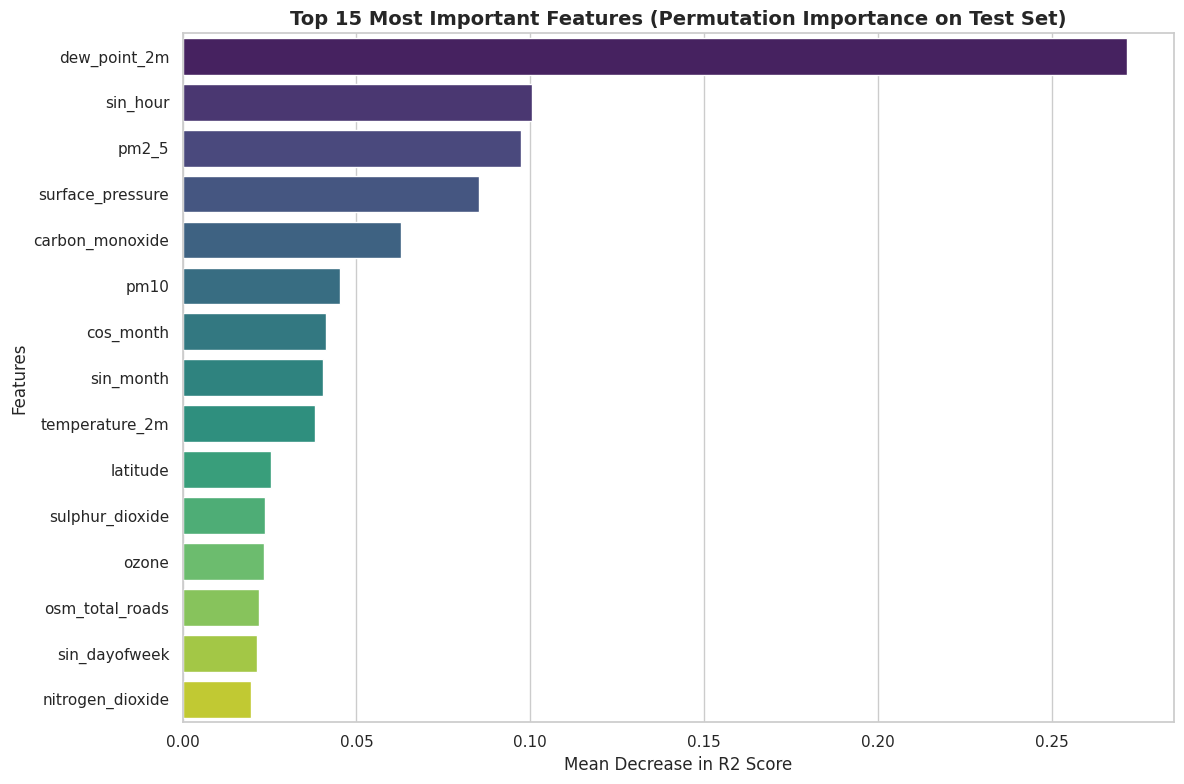

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

print("--- Computing Permutation Feature Importances on Test Set ---")
t0 = time.time()

# Compute permutation importance
perm_importance = permutation_importance(
    best_hgbr, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

print(f"Computed importances in {time.time() - t0:.2f} seconds.")

# Create DataFrame of results
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values(by='Importance_Mean', ascending=False).reset_index(drop=True)

# Plot top 15 features
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Importance_Mean',
    y='Feature',
    data=importance_df.head(15),
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Top 15 Most Important Features (Permutation Importance on Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Mean Decrease in R2 Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

### Step 3: Production Pipeline Design, Serialization, and Deployment Simulation
We will construct a unified Pipeline that performs One-Hot Encoding on categorical features and scales numerical values before passing them directly to our optimized model. This is serialized using `joblib`.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

# Reconstruct scaling & encoding as a ColumnTransformer pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ],
    remainder='drop'
)

# Build complete inference Pipeline
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_hgbr)
])

# Fit the pipeline on raw training set features (X) rather than pre-transformed variables
# We reconstruct the raw training set to demonstrate a perfect zero-leakage workflow
X_raw_train = df.loc[X_train.index, feature_cols]
y_raw_train = df.loc[X_train.index, target_col]

final_pipeline.fit(X_raw_train, y_raw_train)

# Save pipeline to disk
pipeline_filename = 'final_air_quality_pipeline.pkl'
joblib.dump(final_pipeline, pipeline_filename)
print(f"--- Saved Complete Deployment Pipeline to '{pipeline_filename}' ---")

--- Saved Complete Deployment Pipeline to 'final_air_quality_pipeline.pkl' ---


## Test

In [30]:
### test1
# Simulate a real-world client inference payload (API JSON Format)
import json

# Grab a sample raw data point from our dataset (excluding target/ignored columns)
sample_row = df[feature_cols].iloc[2].to_dict()
mock_api_payload = json.dumps(sample_row)

print("--- Mock API Incoming JSON Payload ---")
print(json.dumps(json.loads(mock_api_payload), indent=2)[:400] + "\n... [truncated] ...")

# Load the pipeline in 'production' environments
loaded_pipeline = joblib.load(pipeline_filename)

# Function to perform inference on incoming raw json
def predict_air_quality(json_payload):
    # Parse JSON input
    input_dict = json.loads(json_payload)
    # Convert single entry into a pandas DataFrame
    input_df = pd.DataFrame([input_dict])
    # Predict using the serialized pipeline
    prediction = loaded_pipeline.predict(input_df)[0]
    return prediction

predicted_naqi = predict_air_quality(mock_api_payload)
actual_naqi = df[target_col].iloc[0]

print(f"\n--- Real-World Simulation Inference Results ---")
print(f"Predicted India NAQI: {predicted_naqi:.2f}")
print(f"Actual India NAQI:    {actual_naqi:.2f}")

--- Mock API Incoming JSON Payload ---
{
  "temperature_2m": 23.6,
  "relative_humidity_2m": 43,
  "dew_point_2m": 10.3,
  "surface_pressure": 987.9,
  "wind_speed_10m": 6.6,
  "wind_direction_10m": 169,
  "wind_gusts_10m": 11.9,
  "precipitation": 0.0,
  "cloud_cover": 0,
  "direct_radiation": 0.0,
  "station_id": "CHANDRAPUR_MIDC",
  "latitude": 19.9615,
  "longitude": 79.2961,
  "dew_point_spread": 13.3,
  "wind_u": -1.259,
  "wind_
... [truncated] ...

--- Real-World Simulation Inference Results ---
Predicted India NAQI: 82.37
Actual India NAQI:    109.20


In [28]:
### test2
# Simulate a real-world client inference payload (API JSON Format)
import json

# Grab a sample raw data point from our dataset (excluding target/ignored columns)
sample_row = df[feature_cols].iloc[0].to_dict()
mock_api_payload = json.dumps(sample_row)

print("--- Mock API Incoming JSON Payload ---")
print(json.dumps(json.loads(mock_api_payload), indent=2)[:400] + "\n... [truncated] ...")

# Load the pipeline in 'production' environments
loaded_pipeline = joblib.load(pipeline_filename)

# Function to perform inference on incoming raw json
def predict_air_quality(json_payload):
    # Parse JSON input
    input_dict = json.loads(json_payload)
    # Convert single entry into a pandas DataFrame
    input_df = pd.DataFrame([input_dict])
    # Predict using the serialized pipeline
    prediction = loaded_pipeline.predict(input_df)[0]
    return prediction

predicted_naqi = predict_air_quality(mock_api_payload)
actual_naqi = df[target_col].iloc[0]

print(f"\n--- Real-World Simulation Inference Results ---")
print(f"Predicted India NAQI: {predicted_naqi:.2f}")
print(f"Actual India NAQI:    {actual_naqi:.2f}")

--- Mock API Incoming JSON Payload ---
{
  "temperature_2m": 23.2,
  "relative_humidity_2m": 47,
  "dew_point_2m": 11.3,
  "surface_pressure": 977.9,
  "wind_speed_10m": 8.2,
  "wind_direction_10m": 256,
  "wind_gusts_10m": 14.4,
  "precipitation": 0.0,
  "cloud_cover": 0,
  "direct_radiation": 0.0,
  "station_id": "AKOLA_WEST",
  "latitude": 20.7002,
  "longitude": 77.0082,
  "dew_point_spread": 11.9,
  "wind_u": 7.956,
  "wind_v": 1.
... [truncated] ...

--- Real-World Simulation Inference Results ---
Predicted India NAQI: 112.37
Actual India NAQI:    109.20
